<style>
.reveal{font-family:"Helvetica Neue",Helvetica,Arial,sans-serif;font-size:30px;color:#2d3436}
.reveal-viewport{background:linear-gradient(135deg,#fdfbfb 0%,#ebedee 100%)}
.reveal h1,.reveal h2,.reveal h3{font-family:inherit;text-transform:none;font-weight:700;color:#c2185b;letter-spacing:-0.5px}
.reveal h1{font-size:2em}.reveal h2{font-size:1.5em;border-bottom:4px solid #f8bbd0;padding-bottom:.2em;display:inline-block}
.reveal .slides section{text-align:left}
.reveal .slides section>h1:only-child,.reveal .slides section>h1:first-child{text-align:center}
.reveal strong{color:#ad1457}
.reveal ul,.reveal ol{display:block}
.reveal li{margin:.35em 0}
.reveal table{margin:0 auto;border-collapse:collapse;font-size:.65em;box-shadow:0 4px 14px rgba(0,0,0,.12);border-radius:8px;overflow:hidden}
.reveal table th{background:#c2185b;color:#fff;padding:.5em 1em;text-align:left}
.reveal table td{padding:.4em 1em;border-bottom:1px solid #eee;background:#fff}
.reveal table tr:nth-child(even) td{background:#fdf1f5}
.reveal .jp-OutputArea-output,.reveal .output_area{text-align:center}
.reveal img{max-height:65vh;border-radius:10px;box-shadow:0 6px 20px rgba(0,0,0,.18);border:none;margin:.3em auto}
.reveal pre{width:auto;box-shadow:none;font-size:1.1em;background:#fff;border-left:6px solid #c2185b;border-radius:6px;padding:.6em 1em;display:inline-block;text-align:left}
.reveal .jp-RenderedText pre,.reveal .output_stream pre{color:#2d3436}
.reveal blockquote{width:90%;background:#fff;border-left:6px solid #c2185b;padding:.6em 1em}
.reveal .callout{background:#fff;border-left:6px solid #c2185b;padding:.6em 1em;border-radius:6px;box-shadow:0 4px 14px rgba(0,0,0,.1)}
.reveal .title-slide{text-align:center}
</style>

# Flower Classification

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

# One plot style for the whole notebook
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)

## Photos per class and split

In [2]:
# Import Data
CLASSES = ["rose", "sunflower", "tulip"]
flowers = Path("data")

pd.DataFrame(
    {split: {name: len(list((flowers / split / name).glob("*.jpg"))) for name in CLASSES}
     for split in ["train", "validation", "test"]}
)

,train,validation,test
rose,100,20,10
sunflower,100,20,10
tulip,100,20,10


In [3]:
# Load images helper function
def load_images(split, shuffle):
    """Return a dataset of (images, labels) batches for one split of the sea animals."""
    return keras.utils.image_dataset_from_directory(
        flowers / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=42
    )

## A look at the training photos

Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.


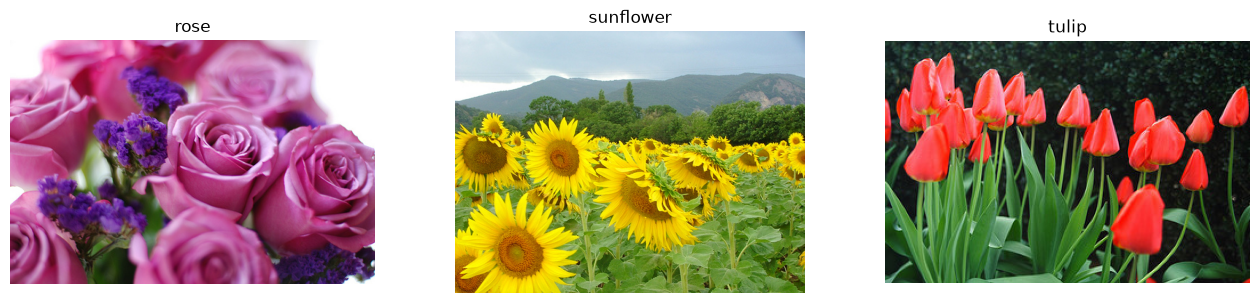

In [4]:
# preview original images from disk
train_ds = load_images("train", shuffle=True)
valid_ds = load_images("validation", shuffle=False)
class_names = train_ds.class_names

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, name in zip(axes, class_names):
    image = keras.utils.load_img(next((flowers / "train" / name).glob("*.jpg")))
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [5]:
# check image size inside our data
images, labels = next(iter(train_ds))
images.shape

TensorShape([32, 160, 160, 3])

## Five photos of every flower

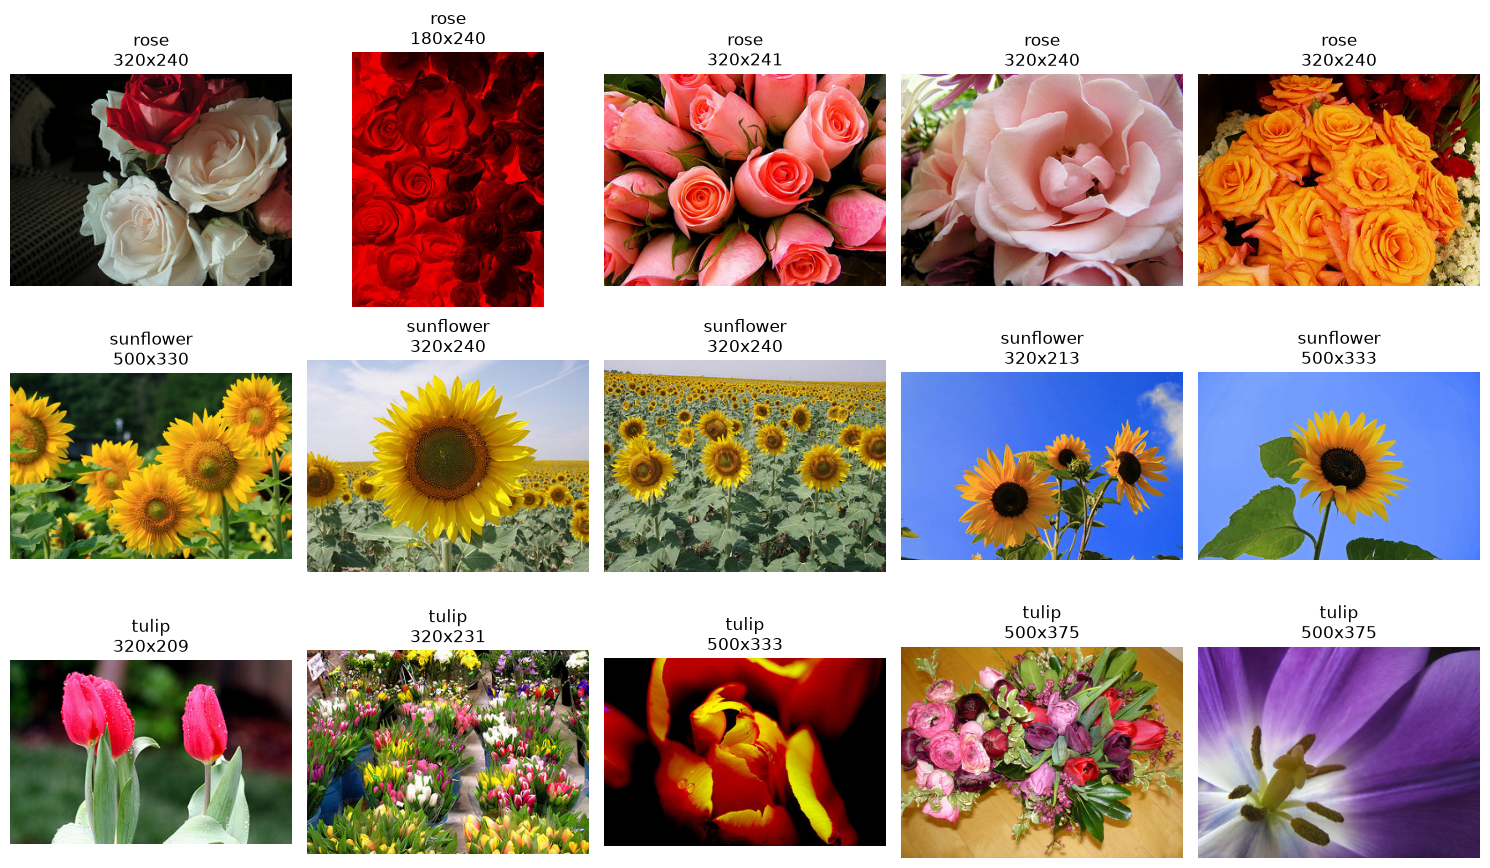

In [6]:
# Show the first 5 photos of every class
n_per_class = 5
fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(15, 9))

for row, flower in enumerate(CLASSES):
    files = sorted(( flowers / "train" / flower).glob("*.jpg"))[:n_per_class]
    for col, file in enumerate(files):
        img = plt.imread(file)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{flower}\n{img.shape[1]}x{img.shape[0]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## What MobileNetV2 predicts out of the box

In [7]:
base = mobilenet_v2.MobileNetV2(
    include_top=True, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

Output shape: (32, 1000)
daisy                0.166
hair_slide           0.119
bee                  0.029


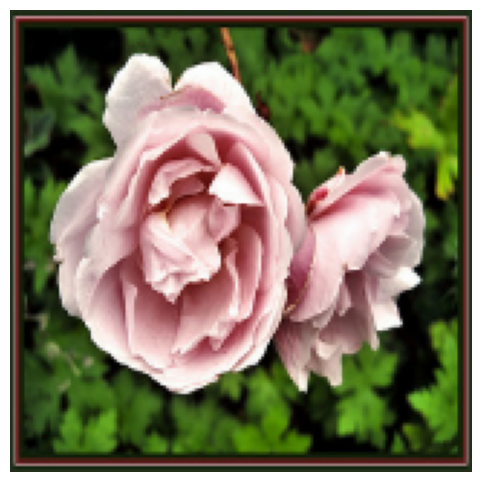

In [8]:
one_image,_ = next(iter(train_ds))

prepared = mobilenet_v2.preprocess_input(one_image)
probabilities = base.predict(prepared, verbose=0)  # shape (1, 1000)
print("Output shape:", probabilities.shape)
for _, name, probability in mobilenet_v2.decode_predictions(probabilities, top=3)[0]:
    print(f"{name:20s} {probability:.3f}")

plt.figure(figsize=(6, 6))
plt.imshow(one_image[0].numpy().astype("uint8"))
plt.axis("off")
plt.show()

# Transfer Learning

Reuse a **pretrained MobileNetV2** as a frozen feature extractor and train only a small classifier on top.

In [9]:
# Base model
base2 = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)
base2.trainable = False

In [15]:
def compile_and_fit(model, epochs, learning_rate=1e-3, initial_epoch=0):
    """Compile a classifier with Adam and train it on the bean images; return the learning curves."""
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    history = model.fit(
        train_ds, validation_data=valid_ds, epochs=epochs, initial_epoch=initial_epoch, verbose=0
    )
    return pd.DataFrame(history.history, index=history.epoch)


def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()

# Model 1: Dense Head

A small dense classifier trained on the extracted features.

In [ ]:
keras.utils.clear_session()
keras.utils.set_random_seed(42)

head = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),
        base2,
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax",
                           kernel_regularizer=keras.regularizers.L2(.01),
        ),
    ]
)

# compile 
head.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])

# fitting
head_history = head.fit(train_ds, validation_data=valid_ds, epochs=30, verbose=0)

logs = pd.DataFrame(head_history.history, index=head_history.epoch)

first_results={}
first_results["head_transfer_model"] = head.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {first_results['head_transfer_model']:.3f}")

/Users/khaldouna/Documents/Neuefische/w5d5/amle-project-flowers/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Validation accuracy: 0.867


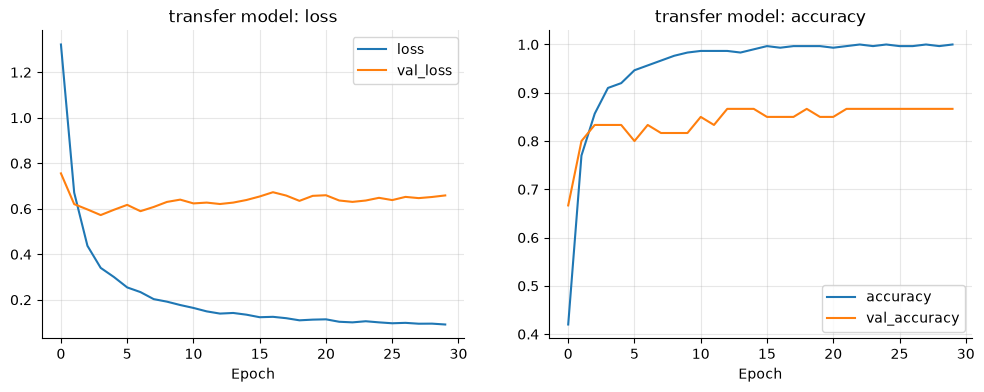

In [41]:
plot_curves(logs, "transfer model")

# Model 2: With Augmentation

Random flips and rotations to reduce overfitting.

## Training with augmentation

/Users/khaldouna/Documents/Neuefische/w5d5/amle-project-flowers/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


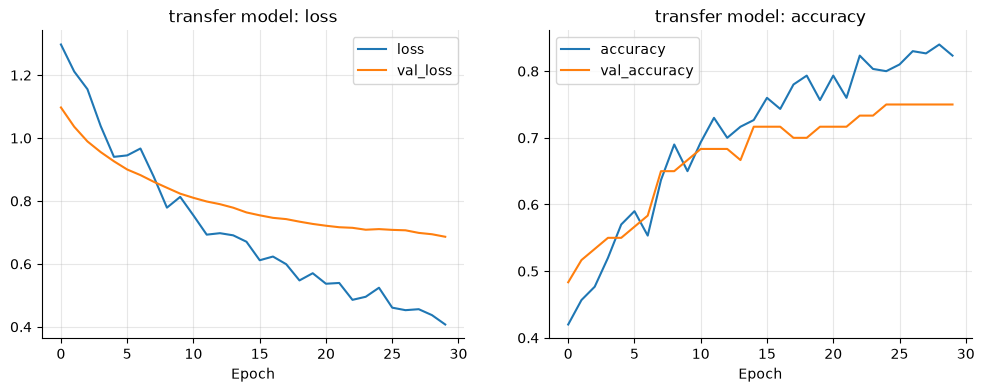

Validation accuracy: 0.750


In [45]:

keras.utils.clear_session()
keras.utils.set_random_seed(42)
augmentation = keras.Sequential(
    [keras.layers.RandomFlip("horizontal"), keras.layers.RandomRotation(0.1), keras.layers.RandomZoom(0.1)]
)
transfer_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        augmentation,
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),
        base2,
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax"),
    ]
)

transfer_model.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-4), metrics=["accuracy"])

history = transfer_model.fit(train_ds, validation_data=valid_ds, epochs=30, verbose=0)

frozen_logs = pd.DataFrame(history.history, index=history.epoch)
plot_curves(frozen_logs, "transfer model")
results={}
results["transfer_model"] = transfer_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {results['transfer_model']:.3f}")

In [46]:
# Save the models
Path("models").mkdir(exist_ok=True)

head.save("models/dense_head.keras")
transfer_model.save("models/augmented_model.keras")

# Testing on Unseen Photos

The 30 test photos are used **once**, at the very end. One photo = **3.3 percentage points**.

In [47]:
# load our models from file
plain_transfer = keras.models.load_model("models/dense_head.keras")
augmented_transfer = keras.models.load_model("models/augmented_model.keras")


In [ ]:
test_ds = load_images("test", shuffle=False)

Found 30 files belonging to 3 classes.


## Test result and confusion matrix

*Model 1: Dense head*

plain transfer model accuracy score:  0.9


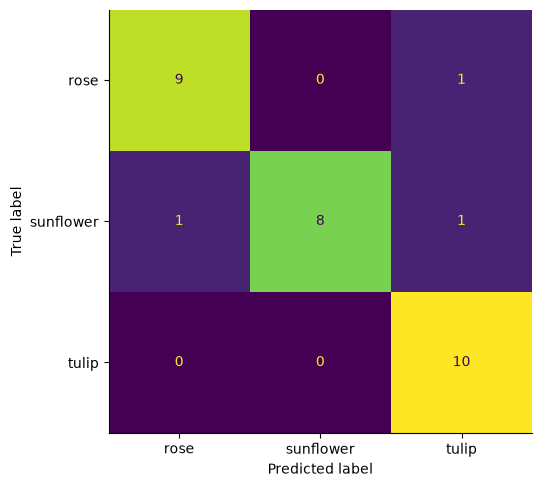

In [49]:
# test augmented model - model 1- 
y_test1 = np.concatenate([labels.numpy() for _, labels in test_ds])
pred1 = plain_transfer.predict(test_ds, verbose=0).argmax(axis=1)

print('plain transfer model accuracy score: ',accuracy_score(y_test1, pred1))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test1, pred1, display_labels=class_names, colorbar=False, ax=ax)
ax.grid(False)
plt.show()

## Misclassified photos

*Model 1: Dense head*

Number of misclassified images: 3


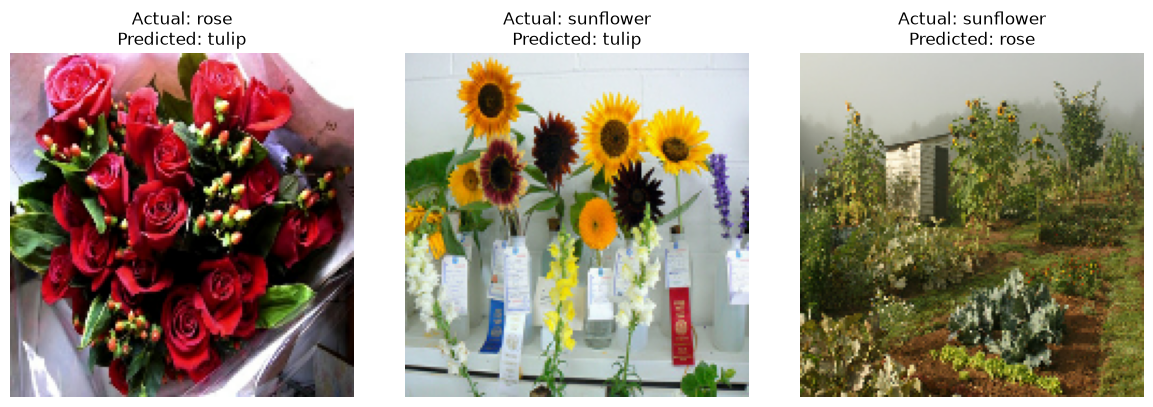

In [50]:
# Find incorrectly classified images
wrong_indices1 = np.where(y_test1 != pred1)[0]

print(f"Number of misclassified images: {len(wrong_indices1)}")

# Collect all test images
X_test1 = np.concatenate([images.numpy() for images, _ in test_ds])

# Display misclassified images
fig, axes = plt.subplots(
    1, len(wrong_indices1),
    figsize=(4 * len(wrong_indices1), 4)
)

if len(wrong_indices1) == 1:
    axes = [axes]

for ax, idx in zip(axes, wrong_indices1):
    ax.imshow(X_test1[idx].astype("uint8"))
    ax.set_title(
        f"Actual: {class_names[y_test1[idx]]}\n"
           f"Predicted: {class_names[pred1[idx]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## Test result and confusion matrix

*Model 2: Augmented*

Augmented_transfer model accuracy score:  0.9


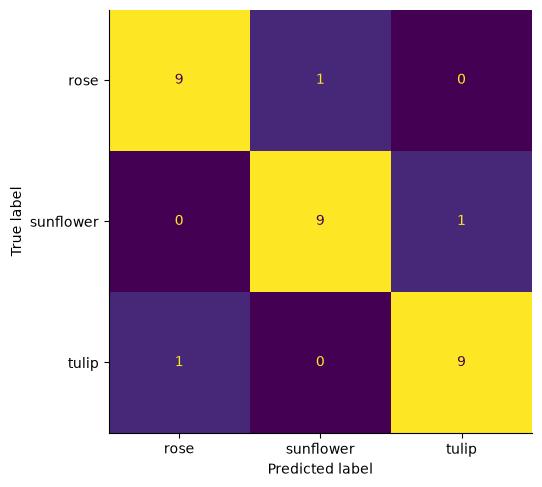

In [51]:
# test augmented model - model 2- 
y_test2 = np.concatenate([labels.numpy() for _, labels in test_ds])
pred = augmented_transfer.predict(test_ds, verbose=0).argmax(axis=1)

print('Augmented_transfer model accuracy score: ',accuracy_score(y_test2, pred))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test2, pred, display_labels=class_names, colorbar=False, ax=ax)
ax.grid(False)
plt.show()

## Misclassified photos

*Model 2: Augmented*

Number of misclassified images: 3


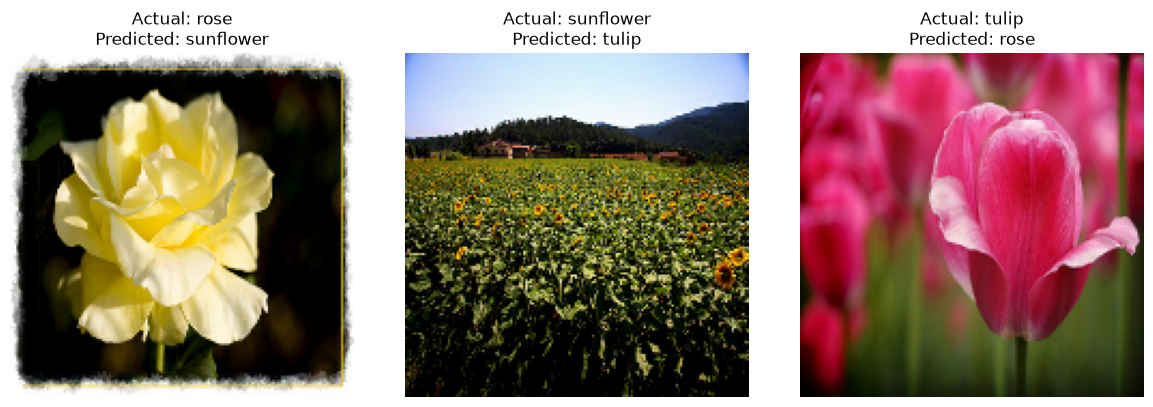

In [52]:
# Find incorrectly classified images
wrong_indices = np.where(y_test2 != pred)[0]

print(f"Number of misclassified images: {len(wrong_indices)}")

# Collect all test images
X_test = np.concatenate([images.numpy() for images, _ in test_ds])

# Display misclassified images
fig, axes = plt.subplots(
    1, len(wrong_indices),
    figsize=(4 * len(wrong_indices), 4)
)

if len(wrong_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, wrong_indices):
    ax.imshow(X_test[idx].astype("uint8"))
    ax.set_title(
        f"Actual: {class_names[y_test2[idx]]}\n"
           f"Predicted: {class_names[pred[idx]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()